# Preprocessing Data Teknikal
## Log Return, Volatilitas Return (Y) & Fitur Teknikal (X1) - RSI, MA, Stochastic Oscillator

**Tesis**: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi (LQ45)
Berdasarkan Analisis Sentimen Menggunakan Metode XGBoost dan LSTM

**Penulis**: Ilda Nurida (NRP 6032251068)
**Pembimbing**: Dr. Ir. Ahmad Saikhu, S.Si, MT.

---

### Tujuan Notebook
1. Memuat `harga_saham_raw.csv` (7 emiten, Jan 2022 - Mei 2026) hasil notebook scraping
2. Menghitung **Log Return** harian per emiten
3. Menghitung **Volatilitas Return** (proksi standar deviasi log return, rolling window) sebagai **Variabel Dependen (Y)**
4. Mengekstraksi **fitur teknikal (X1)**:
   - RSI (Relative Strength Index)
   - Moving Average (MA) - SMA 5, 10, 20 hari
   - Stochastic Oscillator (%K, %D)
5. Menyimpan dataset hasil (`technical_features.csv`) sebagai input pipeline integrasi (X1 + Y)

### Definisi Variabel

| Variabel | Rumus | Keterangan |
|---|---|---|
| Log Return (`r_t`) | `r_t = ln(P_t / P_{t-1})` | `P_t` = harga penutupan hari ke-t |
| Volatilitas Return (`Y`) | `sigma_t = std(r_{t-w+1}, ..., r_t)` | Rolling standard deviation, window `w` hari |

### Catatan
- Data **time series** -> tidak dilakukan random shuffle, urutan kronologis per emiten dijaga
- Perhitungan dilakukan **per emiten** (group by `Kode_Emiten`) agar tidak tercampur antar saham
- Baris awal yang menghasilkan `NaN` (akibat rolling/lag) akan ditangani pada tahap akhir


In [1]:
import os, datetime
from pathlib import Path
import pandas as pd

# ════════════════════════════════════════════════════════════════════
#  PATH KANONIK + IO UTILITAS — IDENTIK DI SEMUA NOTEBOOK
#  (otomatis disisipkan oleh proses audit path)
# ════════════════════════════════════════════════════════════════════
ROOT_HARDCODED = Path(r'E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS'
                      r'\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026')

def cari_root():
    p = Path(os.getcwd())
    for _ in range(8):
        if (p / '03_dataset').exists():
            return p
        p = p.parent
    if ROOT_HARDCODED.exists():
        return ROOT_HARDCODED
    raise FileNotFoundError('ROOT proyek (folder berisi 03_dataset/) tidak ditemukan.')

ROOT = cari_root()
DIR_RAW       = ROOT / '03_dataset' / 'raw'
DIR_PROCESSED = ROOT / '03_dataset' / 'processed'
DIR_FINAL     = ROOT / '03_dataset' / 'final'
DIR_MODEL     = ROOT / '04_model'
DIR_TABEL     = ROOT / '06_dokumen_tesis' / 'tabel'
for _d in (DIR_RAW, DIR_PROCESSED, DIR_FINAL, DIR_TABEL):
    _d.mkdir(parents=True, exist_ok=True)

# Nama file kanonik
F_HARGA    = 'harga_saham_raw.csv'         # DIR_RAW
F_TEKNIKAL = 'technical_features.csv'      # DIR_PROCESSED (satu-satunya lokasi)
F_SENTIMEN = 'skor_sentimen_harian.csv'    # DIR_PROCESSED (nama tunggal)
F_GABUNGAN = 'dataset_gabungan_X1X2Y.csv'  # DIR_FINAL

def muat_csv(path, **kw):
    """LOAD + log sumber absolut. Error eksplisit bila tak ada (TANPA fallback diam-diam)."""
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f'File TIDAK ADA: {path.resolve()}\n'
                                f'   -> Tahap sebelumnya belum menyimpan ke lokasi kanonik ini.')
    df = pd.read_csv(path, **kw)
    print(f'LOAD  : {path.resolve()}  ({len(df):,} baris x {df.shape[1]} kolom)')
    return df

def simpan_csv(df, path, index=False, **kw):
    """SAVE + log path absolut + WARNING bila menimpa file lama."""
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        mt = datetime.datetime.fromtimestamp(path.stat().st_mtime).strftime('%Y-%m-%d %H:%M')
        print(f'OVERWRITE: {path.resolve()}  (file lama {mt} ditimpa)')
    df.to_csv(path, index=index, encoding='utf-8-sig', **kw)
    print(f'SAVE  : {path.resolve()}  ({len(df):,} baris)')

print(f'ROOT : {ROOT.resolve()}')
print(f'  RAW={DIR_RAW.name}/  PROCESSED={DIR_PROCESSED.name}/  FINAL={DIR_FINAL.name}/')


ROOT : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026
  RAW=raw/  PROCESSED=processed/  FINAL=final/


## 1. Import Library & Konfigurasi

- Path input/output (relatif terhadap `02_preprocessing/teknikal/`)
- Parameter window untuk volatilitas, RSI, MA, dan Stochastic Oscillator

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ── Direktori input/output (relatif terhadap 02_preprocessing/teknikal/) ─────
INPUT_DIR            = DIR_RAW
OUTPUT_DIR           = DIR_PROCESSED
OUTPUT_DIR_DASHBOARD = ROOT / 'dashboard' / 'data'

for d in (OUTPUT_DIR, OUTPUT_DIR_DASHBOARD):
    d.mkdir(parents=True, exist_ok=True)

FILE_INPUT  = 'harga_saham_raw.csv'
FILE_OUTPUT = 'technical_features.csv'

URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

# ── Parameter perhitungan ─────────────────────────────────────────────────
VOLATILITY_WINDOW = 20     # rolling window volatilitas return (hari), default 20 (1 bulan bursa)
RSI_PERIOD        = 14    # periode standar RSI
MA_WINDOWS        = [5, 10, 20]   # Simple Moving Average (hari)
STOCH_PERIOD      = 14    # periode %K Stochastic Oscillator
STOCH_SMOOTH_D    = 3     # smoothing %D (SMA dari %K)

plt.rcParams.update({
    'font.family'    : 'Times New Roman',
    'font.size'      : 11,
    'axes.titlesize' : 11,
    'axes.labelsize' : 10,
    'figure.dpi'     : 110,
    'axes.grid'      : True,
    'grid.alpha'     : 0.3,
})

print("=" * 70)
print("  KONFIGURASI PREPROCESSING TEKNIKAL")
print("=" * 70)
print(f"  Input file            : {INPUT_DIR / FILE_INPUT}")
print(f"  Output file           : {OUTPUT_DIR / FILE_OUTPUT}")
print(f"  Window volatilitas    : {VOLATILITY_WINDOW} hari")
print(f"  Periode RSI           : {RSI_PERIOD} hari")
print(f"  Window Moving Average : {MA_WINDOWS}")
print(f"  Periode Stochastic    : %K = {STOCH_PERIOD} hari, %D = SMA {STOCH_SMOOTH_D} hari")
print("=" * 70)

print(f"pandas version : {pd.__version__}")
print(f"numpy version  : {np.__version__}")


  KONFIGURASI PREPROCESSING TEKNIKAL
  Input file            : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv
  Output file           : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv
  Window volatilitas    : 20 hari
  Periode RSI           : 14 hari
  Window Moving Average : [5, 10, 20]
  Periode Stochastic    : %K = 14 hari, %D = SMA 3 hari
pandas version : 3.0.3
numpy version  : 2.4.6


## 2. Memuat Data Harga Saham

Memuat `harga_saham_raw.csv` hasil notebook scraping (7 emiten, OHLCV + Adj Close).
Data diurutkan berdasarkan `Kode_Emiten` lalu `Tanggal` untuk memastikan urutan
kronologis tetap terjaga pada setiap kelompok emiten.


In [3]:
csv_path = INPUT_DIR / FILE_INPUT

df = muat_csv(csv_path)
df.columns = df.columns.str.strip()

date_candidates = ['Tanggal', 'tanggal', 'Date', 'date', 'DATE']
date_col = next((c for c in date_candidates if c in df.columns), None)

if date_col is None:
    raise ValueError(f"Kolom tanggal tidak ditemukan. Kolom tersedia: {list(df.columns)}")

if date_col != 'Tanggal':
    df = df.rename(columns={date_col: 'Tanggal'})

# Format tanggal hasil scraping adalah ISO (YYYY-MM-DD) -> tidak ambigu, dayfirst=False
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce', dayfirst=False)

if df['Tanggal'].isna().any():
    df = df.dropna(subset=['Tanggal']).copy()

df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Tentukan rentang periode penelitian dari data aktual
START_DATE = df['Tanggal'].min().strftime('%Y-%m-%d')
END_DATE   = df['Tanggal'].max().strftime('%Y-%m-%d')

print("Import data telah berhasil")
print(f"Periode data: {START_DATE} s/d {END_DATE}")
print(f"Total baris : {len(df):,}")

LOAD  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\raw\harga_saham_raw.csv  (7,455 baris x 11 kolom)
Import data telah berhasil
Periode data: 2022-01-03 s/d 2026-06-17
Total baris : 7,455


## 3. Perhitungan Log Return & Volatilitas Return
**Log Return**

Log return harian dihitung per emiten menggunakan harga **Adjusted Close**:


$$R_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$




**Volatilitas Return**

Volatilitas return harian dihitung sebagai **rolling standard deviation**
dari log return dengan window `VOLATILITY_WINDOW` hari:


$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(R_i - \bar{R})^2}$$

>Rolling window = 20 hari trading (≈ 1 bulan)

In [4]:
import pandas as pd
import numpy as np
from IPython.display import display

print("=" * 90)
print("CELL — PERHITUNGAN LOG RETURN & VOLATILITY (REVISED)")
print("=" * 90)

# ============================================================
# 1. SORT DATA
# ============================================================
df['Tanggal'] = pd.to_datetime(df['Tanggal'], errors='coerce')

df = (
    df.sort_values(['Kode_Emiten', 'Tanggal'])
      .reset_index(drop=True)
)

kode_emiten_tersedia = sorted(df['Kode_Emiten'].dropna().unique())
print("Kode emiten:", ", ".join(kode_emiten_tersedia))

# ============================================================
# 2. LOG RETURN
# ============================================================
df['Log_Return'] = (
    df.groupby('Kode_Emiten')['Adj Close']
      .transform(lambda x: np.log(x / x.shift(1)))
)

# Handle inf
df['Log_Return'] = (
    df['Log_Return']
    .replace([np.inf, -np.inf], np.nan)
)

# ============================================================
# 3. VOLATILITY RETURN (TARGET DASAR)
# ============================================================
# -- WINSORISASI HARI AKSI KORPORASI (PERBAIKAN) ----------------------------
# Netralkan lonjakan return akibat dividen spesial / spin-off (mis. ADRO
# 28-29 Nov 2024) yang TIDAK terkoreksi Adj Close. Verifikasi tanggal ter-flag
# terhadap kalender aksi korporasi sebelum dipakai final.
THRESH_AKSI = 0.15
df['Flag_AksiKorporasi'] = (df['Log_Return'].abs() > THRESH_AKSI).astype(int)
_flag = df.loc[df['Flag_AksiKorporasi'] == 1, ['Kode_Emiten', 'Tanggal', 'Log_Return']]
print(f"  Hari ter-flag aksi korporasi (|return| > {THRESH_AKSI:.0%}): {len(_flag)}")
if len(_flag):
    print(_flag.sort_values('Tanggal').to_string(index=False))
df.loc[df['Flag_AksiKorporasi'] == 1, 'Log_Return'] = 0.0

df['Volatilitas_Return'] = (
    df.groupby('Kode_Emiten')['Log_Return']
      .transform(
          lambda x: x.rolling(
              window=VOLATILITY_WINDOW,
              min_periods=VOLATILITY_WINDOW
          ).std()
      )
)

# ============================================================
# 4. FEATURE ENGINEERING VOLATILITY (PENTING UNTUK XGBOOST)
# ============================================================
group_vol = df.groupby('Kode_Emiten')['Volatilitas_Return']

df['Vol_Lag1'] = group_vol.shift(1)
df['Vol_Lag2'] = group_vol.shift(2)
df['Vol_Lag3'] = group_vol.shift(3)

df['Vol_MA5'] = (
    group_vol.transform(
        lambda x: x.rolling(5, min_periods=1).mean()
    )
)

df['Vol_STD5'] = (
    group_vol.transform(
        lambda x: x.rolling(5, min_periods=1).std()
    )
)

# ============================================================
# 5. TARGET FORECAST T+1
# ============================================================
df['Target_Volatility'] = (
    df.groupby('Kode_Emiten')['Volatilitas_Return']
      .shift(-1)
)

# ============================================================
# 6. PIVOT TABLE
# ============================================================
tabel_log_return = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Log_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

tabel_volatilitas = (
    df.pivot(
        index='Tanggal',
        columns='Kode_Emiten',
        values='Volatilitas_Return'
    ).reindex(columns=URUTAN_EMITEN)
)

# ============================================================
# 7. SAVE CSV
# ============================================================
tabel_log_return.to_csv(
    OUTPUT_DIR / 'tabel_log_return.csv',
    encoding='utf-8-sig'
)

tabel_volatilitas.to_csv(
    OUTPUT_DIR / 'tabel_volatilitas_return.csv',
    encoding='utf-8-sig'
)

# ============================================================
# 8. RINGKASAN
# ============================================================
print("\nJumlah NaN:")
kolom_cek = [
    'Log_Return',
    'Volatilitas_Return',
    'Vol_Lag1',
    'Vol_Lag2',
    'Vol_Lag3',
    'Target_Volatility'
]

for col in kolom_cek:
    print(f"{col:20s}: {df[col].isna().sum()}")

print("\nStatistik Volatilitas:")
print(
    df['Volatilitas_Return']
    .describe()
    .round(6)
)

print("\nFeature baru berhasil dibuat:")
print("""
✓ Vol_Lag1
✓ Vol_Lag2
✓ Vol_Lag3
✓ Vol_MA5
✓ Vol_STD5
✓ Target_Volatility
""")

print(f"\nDisimpan: {OUTPUT_DIR / 'tabel_log_return.csv'}")
print(f"Disimpan: {OUTPUT_DIR / 'tabel_volatilitas_return.csv'}")

CELL — PERHITUNGAN LOG RETURN & VOLATILITY (REVISED)
Kode emiten: ADMR, ADRO, AKRA, ITMG, MEDC, PGAS, PTBA
  Hari ter-flag aksi korporasi (|return| > 15%): 21
Kode_Emiten    Tanggal  Log_Return
       ADMR 2022-01-04    0.298732
       ADMR 2022-01-05    0.293162
       ADMR 2022-01-06    0.219859
       ADMR 2022-01-07    0.223144
       ADMR 2022-01-10    0.221036
       ADMR 2022-01-11    0.218915
       ADMR 2022-01-12    0.219748
       ADMR 2022-01-19    0.171148
       ADMR 2022-03-02    0.216115
       ADRO 2022-03-04    0.152507
       MEDC 2022-08-23    0.178248
       PTBA 2023-06-26    0.189605
       PTBA 2023-06-27   -0.161586
       MEDC 2023-09-01    0.186984
       ADRO 2024-11-28    0.177196
       ADRO 2024-11-29   -0.282863
       ADRO 2024-12-09    0.152908
       ADMR 2025-03-06    0.151231
       AKRA 2025-04-10    0.200671
       ADMR 2025-10-08    0.222238
       MEDC 2026-05-21   -0.160623

Jumlah NaN:
Log_Return          : 7
Volatilitas_Return  : 140
Vol_Lag1

## 3.1 Statistik Deskriptif Log Return & Volatilitas Return (Tabel 4.1 & 4.2)
**Statistik deskriptif Log Return**

Statistik deskriptif Log Return per emiten: jumlah observasi, rata-rata,
standar deviasi, nilai minimum-maksimum, kuartil, skewness, dan kurtosis.
Tabel ini menggambarkan karakteristik distribusi return harian masing-masing
emiten sektor energi.

**Statistik deskriptif Volatilitas Return**


Statistik deskriptif Volatilitas Return (Variabel Y) per emiten: jumlah
observasi, rata-rata, standar deviasi, nilai minimum-maksimum, kuartil, dan
rata-rata volatilitas tahunan (anualisasi dengan faktor akar 252 hari bursa).




> Rolling window = 20 hari trading (≈ 1 bulan)

In [5]:
#Statistik deskriptif log return per emiten
rows_return = []
for kode in URUTAN_EMITEN:
    s = df[df['Kode_Emiten'] == kode]['Log_Return'].dropna()
    rows_return.append({
        'Emiten'   : kode,
        'N (Hari)' : len(s),
        'Mean'     : round(s.mean(), 6),
        'Std Dev'  : round(s.std(), 6),
        'Min'      : round(s.min(), 6),
        'Q1 (25%)' : round(s.quantile(0.25), 6),
        'Median'   : round(s.median(), 6),
        'Q3 (75%)' : round(s.quantile(0.75), 6),
        'Max'      : round(s.max(), 6),
        'Skewness' : round(s.skew(), 4),
        'Kurtosis' : round(s.kurtosis(), 4),
    })

tabel_4_1 = pd.DataFrame(rows_return).set_index('Emiten')

path_tabel_4_1 = OUTPUT_DIR / 'tabel_4_1_deskriptif_log_return.csv'
tabel_4_1.to_csv(path_tabel_4_1, encoding='utf-8-sig')

print("=" * 80)
print("  TABEL 4.1 - STATISTIK DESKRIPTIF LOG RETURN PER EMITEN")
print("=" * 80)
display(tabel_4_1)

#Statistik deskriptif volatilitas return per emiten
rows_vol = []
for kode in URUTAN_EMITEN:
    s = df[df['Kode_Emiten'] == kode]['Volatilitas_Return'].dropna()
    rows_vol.append({
        'Emiten'            : kode,
        'N (Hari)'          : len(s),
        'Mean'              : round(s.mean(), 6),
        'Std Dev'           : round(s.std(), 6),
        'Min'               : round(s.min(), 6),
        'Q1 (25%)'          : round(s.quantile(0.25), 6),
        'Median'            : round(s.median(), 6),
        'Q3 (75%)'          : round(s.quantile(0.75), 6),
        'Max'               : round(s.max(), 6),
        'Vol Annual (Mean)' : round((s * np.sqrt(252)).mean(), 4),
    })

tabel_4_2 = pd.DataFrame(rows_vol).set_index('Emiten')

path_tabel_4_2 = OUTPUT_DIR / 'tabel_4_2_deskriptif_volatilitas.csv'
tabel_4_2.to_csv(path_tabel_4_2, encoding='utf-8-sig')

print("=" * 80)
print("  TABEL 4.2 - STATISTIK DESKRIPTIF VOLATILITAS RETURN PER EMITEN")
print("=" * 80)
display(tabel_4_2)

print(f"\nDisimpan: {path_tabel_4_2}")
print(f"\nDisimpan: {path_tabel_4_1}")



  TABEL 4.1 - STATISTIK DESKRIPTIF LOG RETURN PER EMITEN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Skewness,Kurtosis
Emiten,,,,,,,,,,
ADRO,1064,0.000816,0.024504,-0.114739,-0.012689,0.0,0.013245,0.115750,0.3068,2.1749
ADMR,1064,0.000087,0.034592,-0.130362,-0.020290,0.0,0.018221,0.144303,0.3758,1.1936
ITMG,1064,0.000846,0.019932,-0.072238,-0.008523,0.0,0.009646,0.117899,0.3674,3.8367
PTBA,1064,0.000675,0.019543,-0.072759,-0.008990,0.0,0.008889,0.089380,0.3795,3.1762
MEDC,1064,0.000877,0.030432,-0.119545,-0.016581,0.0,0.017778,0.145417,0.2801,1.3606
AKRA,1064,0.000430,0.024634,-0.121214,-0.011988,0.0,0.013367,0.091901,0.0270,2.0383
PGAS,1064,0.000529,0.020324,-0.145050,-0.009860,0.0,0.010782,0.107631,-0.1460,4.4825


  TABEL 4.2 - STATISTIK DESKRIPTIF VOLATILITAS RETURN PER EMITEN


,N (Hari),Mean,Std Dev,Min,Q1 (25%),Median,Q3 (75%),Max,Vol Annual (Mean)
Emiten,,,,,,,,,
ADRO,1045,0.023686,0.006686,0.009189,0.018842,0.022831,0.028216,0.043569,0.3760
ADMR,1045,0.032861,0.010315,0.009526,0.024607,0.031815,0.039838,0.063910,0.5217
ITMG,1045,0.018119,0.008254,0.004436,0.011047,0.016769,0.023914,0.039396,0.2876
PTBA,1045,0.018300,0.006771,0.005605,0.013253,0.017519,0.022368,0.038816,0.2905
MEDC,1045,0.029488,0.008510,0.011549,0.023851,0.028618,0.034421,0.054869,0.4681
AKRA,1045,0.023606,0.007244,0.009007,0.018701,0.023037,0.028346,0.044103,0.3747
PGAS,1045,0.019125,0.006301,0.007216,0.014697,0.018486,0.022351,0.042946,0.3036



Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_4_2_deskriptif_volatilitas.csv

Disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\tabel_4_1_deskriptif_log_return.csv


In [6]:
print(df[df['Kode_Emiten']=='PGAS']['Log_Return'].dropna().kurtosis())  # default: excess (Fisher)
print(df[df['Kode_Emiten']=='PGAS']['Log_Return'].dropna().kurt())       # sama

4.48254382748373
4.48254382748373


## 3.2 Grafik Time Series Log Return (Gambar 4.1)

Grafik pergerakan Log Return harian untuk masing-masing emiten selama periode
penelitian. Fluktuasi return yang besar mengindikasikan periode volatilitas
tinggi pada saham tersebut.


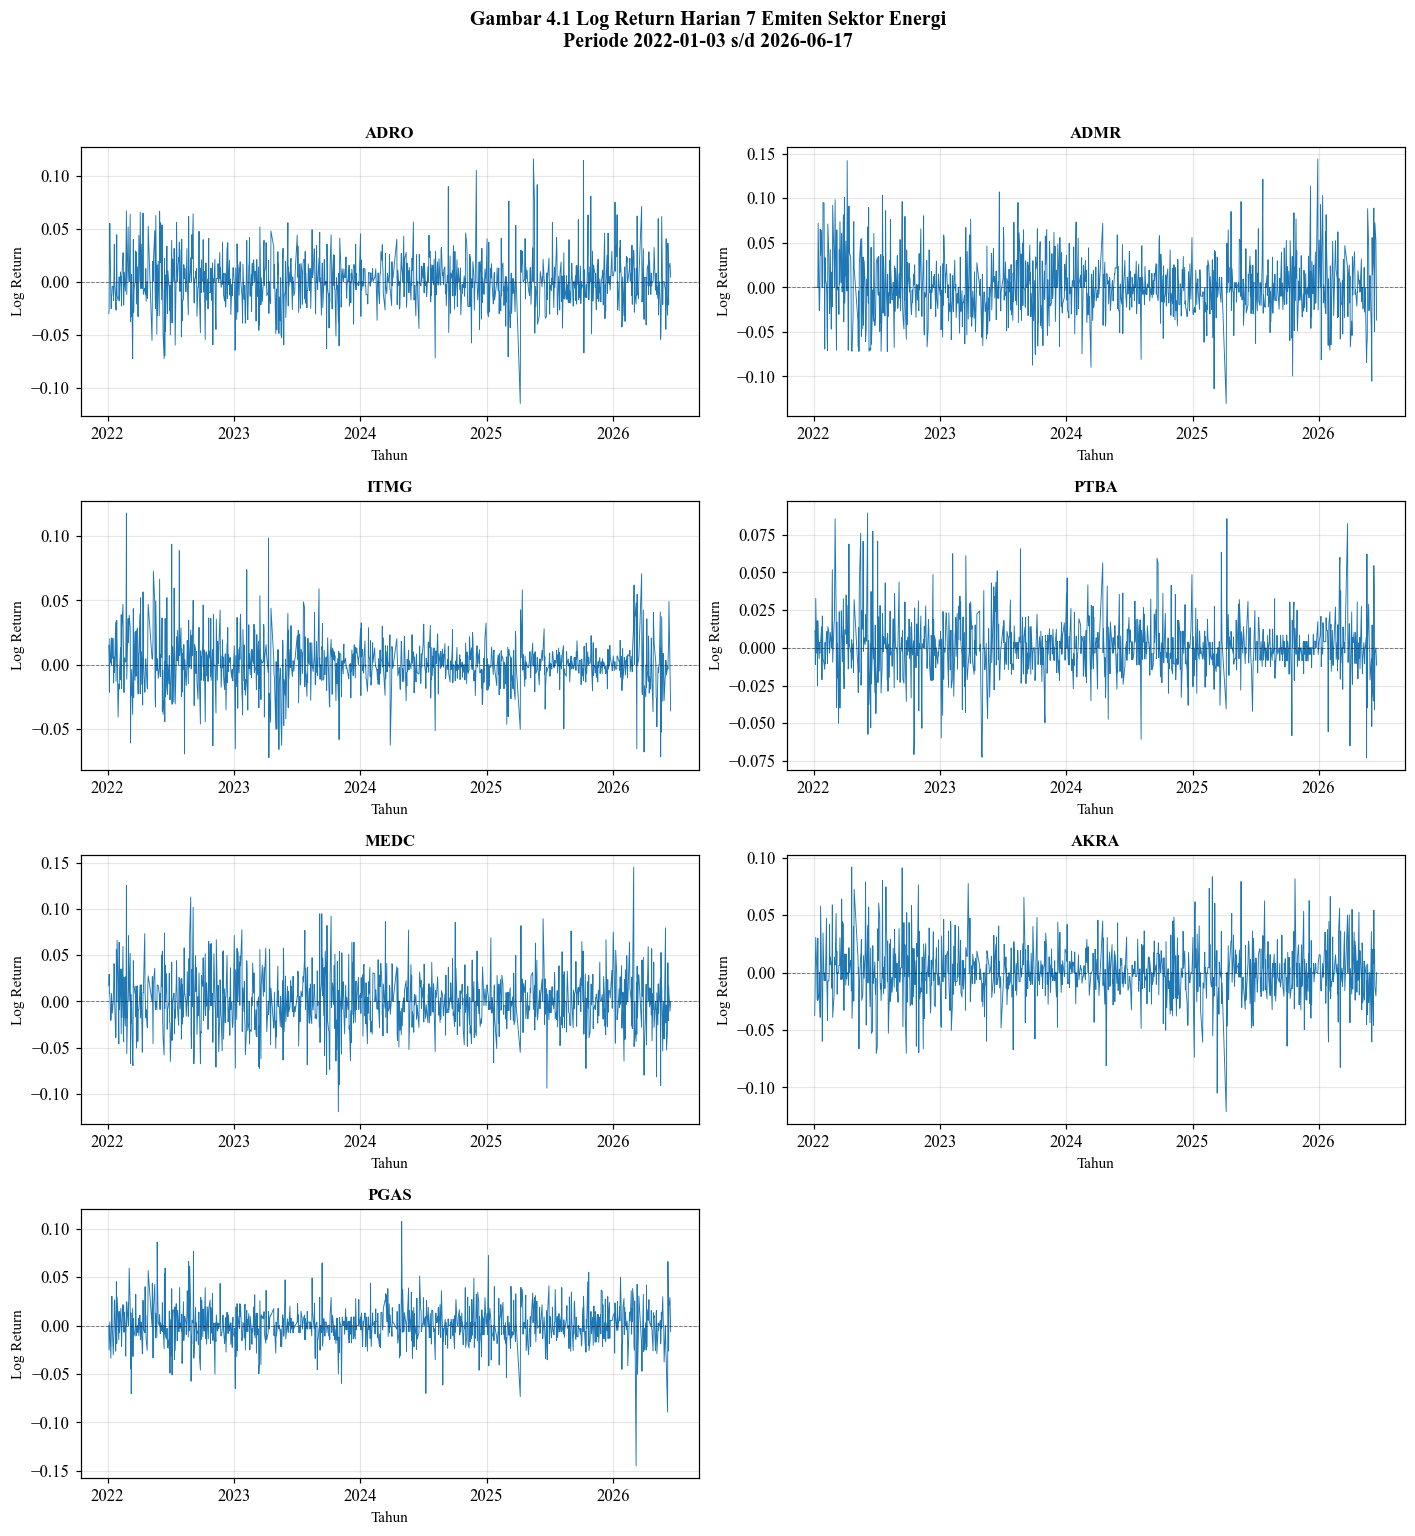

Gambar tersimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_4_1_log_return.png


In [7]:
fig, axes = plt.subplots(4, 2, figsize=(13, 14))
axes = axes.flatten()

for i, kode in enumerate(URUTAN_EMITEN):
    sub = df[df['Kode_Emiten'] == kode]
    ax  = axes[i]
    ax.plot(sub['Tanggal'], sub['Log_Return'], color='tab:blue', linewidth=0.6)
    ax.axhline(0, color='black', linewidth=0.6, linestyle='--', alpha=0.5)
    ax.set_title(f'{kode}', fontweight='bold')
    ax.set_xlabel('Tahun')
    ax.set_ylabel('Log Return')
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

axes[-1].axis('off')

fig.suptitle('Gambar 4.1 Log Return Harian 7 Emiten Sektor Energi\n'
              f'Periode {START_DATE} s/d {END_DATE}',
              fontsize=13, fontweight='bold', y=0.995)
fig.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar_4_1 = OUTPUT_DIR_DASHBOARD / 'gambar_4_1_log_return.png'
fig.savefig(path_gambar_4_1, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar tersimpan: {path_gambar_4_1}")

## 4. Fitur Teknikal: RSI (Relative Strength Index)

RSI mengukur kekuatan momentum harga dalam rentang 0-100:

$$ RSI_t = 100 - \frac{100}{1 + RS_t}, \qquad RS_t = \frac{\text{rata-rata gain}_{14}}{\text{rata-rata loss}_{14}} $$

Dihitung menggunakan metode **Wilder's smoothing** (exponential moving average
dengan `alpha = 1/periode`), sesuai standar perhitungan RSI 14 hari.


In [8]:
# ==============================================================================
# CELL — PERHITUNGAN RELATIVE STRENGTH INDEX (RSI14) REVISED
# ==============================================================================

def hitung_rsi(series, period=RSI_PERIOD):
    """
    Menghitung RSI menggunakan metode standar Wilder's Smoothing (EMA).
    Aman dari pembagian dengan nol (DivisionByZero).
    """
    delta = series.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)

    # Menggunakan alpha=1/period sesuai standar indikator teknikal orisinal
    avg_gain = gain.ewm(alpha=1/period, adjust=False, min_periods=period).mean()
    avg_loss = loss.ewm(alpha=1/period, adjust=False, min_periods=period).mean()

    # Hitung Relative Strength (RS)
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))

    # Penanganan kondisi batas ekstrem (Handling division by zero / flat price)
    rsi = rsi.where(~(avg_loss == 0), 100)
    rsi = rsi.where(~((avg_gain == 0) & (avg_loss == 0)), 50)

    return rsi

print("=" * 70)
print(" ⚙️ MEMULAI PERHITUNGAN INDIKATOR RSI")
print("=" * 70)

# Pastikan data terurut kronologis sebelum kalkulasi runtun waktu
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Eksekusi kalkulasi RSI per kelompok emiten dengan melemparkan fungsi langsung
# Pendekatan ini mempertahankan struktur indeks asli df tanpa risiko pergeseran baris
df['RSI'] = df.groupby('Kode_Emiten')['Adj Close'].transform(hitung_rsi, period=RSI_PERIOD)

# Sinkronisasi nama kolom dengan konfigurasi tesis awal (KOLOM_X1 menggunakan RSI14)
df['RSI14'] = df['RSI']

print(f"  ✅ RSI ({RSI_PERIOD} hari) sukses dihitung untuk semua emiten.")
print(f"  Total NaN pada fitur RSI14: {df['RSI14'].isna().sum()} baris awal (warm-up)")
print("-" * 70)

# Pembentukan tabel pivot visual monitoring laporan data akhir
tabel_rsi = (
    df[['Tanggal', 'Kode_Emiten', 'RSI14']]
      .dropna(subset=['RSI14'])
      .sort_values(['Tanggal', 'Kode_Emiten'])
      .pivot(index='Tanggal', columns='Kode_Emiten', values='RSI14')
      .reindex(columns=URUTAN_EMITEN)
)

# Menampilkan 5 baris teratas tabel pivot di lingkungan notebook
display(tabel_rsi.head())


 ⚙️ MEMULAI PERHITUNGAN INDIKATOR RSI
  ✅ RSI (14 hari) sukses dihitung untuk semua emiten.
  Total NaN pada fitur RSI14: 98 baris awal (warm-up)
----------------------------------------------------------------------


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-21,24.416913,96.226023,82.541523,79.100057,87.601134,22.101672,47.806317
2022-01-24,23.005329,96.523421,85.819443,81.132707,73.307833,21.769453,40.106521
2022-01-25,21.040415,96.523421,79.504038,70.117036,63.297753,20.445610,38.212781
2022-01-26,21.040415,96.523421,80.488056,73.929066,70.130375,17.819827,52.657043
2022-01-27,32.229066,96.523421,84.027392,75.604737,70.130375,16.787879,47.657821


## 5. Fitur Teknikal: Moving Average (MA)

Simple Moving Average (SMA) dihitung untuk beberapa periode (5, 10, 20 hari)
sebagai indikator tren harga jangka pendek-menengah:

$$ MA_t^{(n)} = \frac{1}{n}\sum_{i=0}^{n-1} P_{t-i} $$


In [9]:
# ==============================================================================
# CELL — PERHITUNGAN SIMPLE MOVING AVERAGE (MA5, MA10, MA20) REVISED
# ==============================================================================

# 1. Perhitungan Moving Average secara Efisien Tanpa Lambda
for window in MA_WINDOWS:
    # Menggunakan nama kolom tanpa underscore (MA5, MA10, MA20) sesuai KOLOM_X1
    col_name = f'MA{window}'
    
    # Memanggil method rolling langsung di dalam transform untuk efisiensi memori
    df[col_name] = (
        df.groupby('Kode_Emiten')['Adj Close']
          .transform(lambda x: x.rolling(window=window, min_periods=window).mean())
    )

# Perbarui daftar nama kolom MA beraliansi dengan konfigurasi tesis awal
ma_cols = [f'MA{w}' for w in MA_WINDOWS]

print("=" * 80)
print(" ⚙️ MEMULAI GENERASI TABEL MONITORING MOVING AVERAGE")
print("=" * 80)

# 2. Pembuatan Tabel Terpisah per Jenis MA: Baris=Tanggal, Kolom=7 Emiten
tabel_ma = {}
for ma in ma_cols:
    tabel = (
        df.pivot(index='Tanggal', columns='Kode_Emiten', values=ma)
          .reindex(columns=URUTAN_EMITEN)
    )
    tabel_ma[ma] = tabel.dropna(how='all')  # Buang baris awal yang seluruhnya NaN

    print("=" * 80)
    print(f" 📊 TABEL {ma} - 7 EMITEN KANDIDAT TESIS")
    print("=" * 80)
    
    # Menampilkan gabungan 5 baris pertama dan 5 baris terakhir untuk ringkasan laporan
    display(pd.concat([
        tabel_ma[ma].head(5),
        tabel_ma[ma].tail(5)
    ]).round(2))
    print(f"  Total NaN pada fitur {ma}: {df[ma].isna().sum()} baris awal (warm-up)")
    print()


 ⚙️ MEMULAI GENERASI TABEL MONITORING MOVING AVERAGE
 📊 TABEL MA5 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-07,786.92,230.97,9275.29,1194.04,392.52,615.07,874.48
2022-01-10,788.95,293.86,9315.00,1203.70,395.80,613.32,863.02
2022-01-11,791.65,369.55,9338.37,1215.13,396.46,613.32,849.66
2022-01-12,796.38,460.64,9350.05,1217.76,395.47,612.74,841.38
2022-01-13,795.03,540.60,9441.17,1227.43,393.84,614.63,840.11
2026-06-10,2246.00,1471.00,21930.00,2509.00,1180.09,1217.00,1505.88
2026-06-11,2242.00,1488.00,21985.00,2503.26,1169.38,1224.00,1487.00
2026-06-12,2250.00,1523.00,22300.00,2509.00,1173.27,1230.00,1489.00
2026-06-15,2280.00,1565.00,22600.00,2531.93,1181.44,1242.00,1526.00


  Total NaN pada fitur MA5: 28 baris awal (warm-up)

 📊 TABEL MA10 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-14,785.57,423.82,9389.77,1212.49,391.54,612.45,856.34
2022-01-17,781.85,482.72,9459.86,1218.64,392.36,607.94,849.98
2022-01-18,779.14,535.41,9501.91,1223.91,393.18,605.75,842.34
2022-01-19,778.81,595.33,9543.97,1227.43,394.49,602.92,836.61
2022-01-20,779.14,655.25,9600.04,1232.70,397.11,597.31,833.75
2026-06-10,2259.00,1466.00,22127.50,2576.83,1202.97,1238.50,1607.61
2026-06-11,2254.00,1461.50,22090.00,2556.77,1199.08,1236.00,1581.95
2026-06-12,2252.00,1468.00,22165.00,2535.75,1196.16,1232.00,1559.29
2026-06-15,2254.00,1481.00,22292.50,2520.46,1196.83,1231.00,1547.61


  Total NaN pada fitur MA10: 63 baris awal (warm-up)

 📊 TABEL MA20 - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-28,774.92,661.79,9679.47,1230.50,402.15,586.58,846.79
2022-01-31,772.72,714.43,9726.78,1234.46,405.96,581.41,846.16
2022-02-02,771.20,760.95,9759.49,1236.87,408.42,577.23,844.88
2022-02-03,770.86,806.45,9779.94,1238.85,411.73,573.63,845.36
2022-02-04,768.83,849.63,9807.39,1240.83,414.68,569.55,846.00
2026-06-10,2316.50,1525.50,22778.75,2620.31,1308.61,1315.00,1658.94
2026-06-11,2303.00,1510.00,22698.75,2610.75,1291.33,1305.50,1648.19
2026-06-12,2291.00,1500.00,22675.00,2600.72,1274.54,1295.25,1638.95
2026-06-15,2281.00,1494.25,22646.25,2590.69,1257.10,1283.75,1631.95


  Total NaN pada fitur MA20: 133 baris awal (warm-up)



## 6. Fitur Teknikal: Stochastic Oscillator

Stochastic Oscillator mengukur posisi harga penutupan relatif terhadap
rentang harga tertinggi-terendah dalam periode tertentu:

$$ \%K_t = 100 \times \frac{C_t - L_{n}}{H_{n} - L_{n}} $$

$$ \%D_t = SMA(\%K_t, m) $$

dengan `H_n` dan `L_n` adalah harga tertinggi (`High`) dan terendah (`Low`)
selama `n` hari terakhir (`STOCH_PERIOD`), dan `%D` adalah SMA dari `%K`
selama `m` hari (`STOCH_SMOOTH_D`).


In [10]:
# ==============================================================================
# CELL — PERHITUNGAN STOCHASTIC OSCILLATOR (Stoch_K & Stoch_D) REVISED
# ==============================================================================

def hitung_stochastic(group, n=STOCH_PERIOD, m=STOCH_SMOOTH_D):
    """Hitung %K dan %D Stochastic Oscillator untuk satu grup emiten."""
    lowest_low   = group['Low'].rolling(window=n, min_periods=n).min()
    highest_high = group['High'].rolling(window=n, min_periods=n).max()

    # Menggunakan denominator untuk mengantisipasi saham flat (pembagian dengan nol)
    denom = highest_high - lowest_low
    percent_k = 100 * (group['Adj Close'] - lowest_low) / denom
    percent_k = percent_k.where(denom != 0, 50.0) # Isi 50 jika harga benar-benar flat
    
    percent_d = percent_k.rolling(window=m, min_periods=m).mean()

    # Nama kolom disesuaikan dengan KOLOM_X1 di konfigurasi awal (tanpa simbol %)
    return pd.DataFrame({'Stoch_K': percent_k, 'Stoch_D': percent_d}, index=group.index)

print("=" * 80)
print(" ⚙️ MEMULAI PERHITUNGAN INDIKATOR STOCHASTIC OSCILLATOR")
print("=" * 80)

# Memastikan urutan data runtun waktu panel aman
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# Eksekusi fungsi per grup emiten
stoch_result = (
    df.groupby('Kode_Emiten', group_keys=False)
      .apply(lambda g: hitung_stochastic(g, n=STOCH_PERIOD, m=STOCH_SMOOTH_D))
)

# Integrasikan hasil ke dataframe utama tesis Anda
df['Stoch_K'] = stoch_result['Stoch_K']
df['Stoch_D'] = stoch_result['Stoch_D']

print(f"  ✅ Stochastic Oscillator (K={STOCH_PERIOD}, D=SMA {STOCH_SMOOTH_D}) sukses dihitung.")
print(f"  Total NaN pada fitur Stoch_K: {df['Stoch_K'].isna().sum()} baris awal (warm-up)")

# ── Tabel Ringkasan Monitoring Laporan Tesis (Format Output Jurnal) ──
for metric, nama in [('Stoch_K', '%K'), ('Stoch_D', '%D')]:
    tabel = (
        df.pivot(index='Tanggal', columns='Kode_Emiten', values=metric)
          .reindex(columns=URUTAN_EMITEN)
          .dropna(how='all')
    )

    # Susun tabel gabungan: head(5) + baris pemisah (...) + tail(5)
    tabel_fmt = tabel.round(2).astype(object)
    tabel_display = pd.concat([
        tabel_fmt.head(5),
        pd.DataFrame([['...'] * len(tabel_fmt.columns)],
                      columns=tabel_fmt.columns,
                      index=['...']),
        tabel_fmt.tail(5)
    ])
    
    tabel_display.index = tabel_display.index.map(
        lambda x: x.strftime('%Y-%m-%d') if hasattr(x, 'strftime') else x
    )
    tabel_display.index.name = 'Tanggal'

    print("\n" + "=" * 80)
    print(f" 📊 TABEL STOCHASTIC OSCILLATOR {nama} - 7 EMITEN KANDIDAT TESIS")
    print("=" * 80)
    display(tabel_display)


 ⚙️ MEMULAI PERHITUNGAN INDIKATOR STOCHASTIC OSCILLATOR
  ✅ Stochastic Oscillator (K=14, D=SMA 3) sukses dihitung.
  Total NaN pada fitur Stoch_K: 91 baris awal (warm-up)

 📊 TABEL STOCHASTIC OSCILLATOR %K - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-20,-463.06,84.8,-451.49,-486.13,-44.52,-151.95,-268.4
2022-01-21,-482.47,87.84,-517.41,-581.98,-53.02,-127.14,-254.48
2022-01-24,-487.13,88.7,-487.37,-608.34,-82.48,-129.9,-306.74
2022-01-25,-455.8,87.46,-432.91,-619.8,-104.82,-140.92,-378.96
2022-01-26,-455.8,86.08,-467.49,-757.47,-70.07,-123.42,-361.47
...,...,...,...,...,...,...,...
2026-06-10,76.0,67.9,29.89,38.52,10.13,37.74,33.33
2026-06-11,56.0,49.38,53.33,12.88,26.25,55.56,26.32
2026-06-12,68.0,76.54,87.63,10.55,30.96,48.89,31.58



 📊 TABEL STOCHASTIC OSCILLATOR %D - 7 EMITEN KANDIDAT TESIS


Kode_Emiten,ADRO,ADMR,ITMG,PTBA,MEDC,AKRA,PGAS
Tanggal,,,,,,,
2022-01-24,-477.55,87.11,-485.42,-558.82,-60.01,-136.33,-276.54
2022-01-25,-475.13,88.0,-479.23,-603.38,-80.11,-132.65,-313.39
2022-01-26,-466.24,87.42,-462.59,-661.87,-85.79,-131.41,-349.05
2022-01-27,-452.16,85.81,-447.64,-714.53,-81.65,-121.69,-372.12
2022-01-28,-449.62,85.77,-425.94,-764.91,-53.53,-106.35,-349.28
...,...,...,...,...,...,...,...
2026-06-10,49.56,63.15,21.26,12.11,9.71,25.46,19.62
2026-06-11,62.67,65.43,34.64,22.2,17.15,42.42,27.78
2026-06-12,66.67,64.61,56.95,20.65,22.45,47.39,30.41


In [11]:
# ==============================================================================
# CELL — REKAYASA FITUR SISA: EMA, BOLLINGER BANDS, DAN VOLUME MOMENTUM
# ==============================================================================

print("=" * 90)
print(" ⚙️ MEMULAI PERHITUNGAN FITUR TEKNIKAL SISA (EMA, BB, & VOLUME)")
print("=" * 90)

# Pastikan data terurut secara kronologis per emiten
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# ------------------------------------------------------------------------------
# A. PERHITUNGAN EMA12 & EMA26 (Exponential Moving Average)
# ------------------------------------------------------------------------------
df['EMA12'] = df.groupby('Kode_Emiten')['Adj Close'].transform(lambda x: x.ewm(span=12, adjust=False).mean())
df['EMA26'] = df.groupby('Kode_Emiten')['Adj Close'].transform(lambda x: x.ewm(span=26, adjust=False).mean())


# ------------------------------------------------------------------------------
# B. PERHITUNGAN BOLLINGER BANDS (BB_Upper, BB_Lower, BB_Width, BB_PctB)
# ------------------------------------------------------------------------------
# Menggunakan window 20 hari sesuai standar instrumen John Bollinger
BB_WINDOW = 20
df['BB_Mid'] = df.groupby('Kode_Emiten')['Adj Close'].transform(lambda x: x.rolling(window=BB_WINDOW).mean())
df['BB_Std'] = df.groupby('Kode_Emiten')['Adj Close'].transform(lambda x: x.rolling(window=BB_WINDOW).std())

# Formula Garis Atas dan Bawah (2 kali standar deviasi)
df['BB_Upper'] = df['BB_Mid'] + (2 * df['BB_Std'])
df['BB_Lower'] = df['BB_Mid'] - (2 * df['BB_Std'])

# Indikator Lebar Pita (Bollinger Band Width) -> Sangat penting untuk XGBoost
df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Mid']

# Indikator Posisi Harga relatif terhadap Pita (%B)
# Menggunakan penanganan division by zero jika bursa flat / suspensi
denom_bb = df['BB_Upper'] - df['BB_Lower']
df['BB_PctB'] = (df['Adj Close'] - df['BB_Lower']) / denom_bb
df['BB_PctB'] = df['BB_PctB'].where(denom_bb != 0, 0.5)

# Hapus kolom bantuan sementara agar tidak mengotori dataset final
df = df.drop(columns=['BB_Mid', 'BB_Std'])

# ------------------------------------------------------------------------------
# C. PERHITUNGAN PERUBAHAN & MOMENTUM VOLUME (Volume_Change, Volume_MA5) - FIXED
# ------------------------------------------------------------------------------
# Perubahan volume harian (persentase) -> Diperbaiki menggunakan pct_change(1)
df['Volume_Change'] = df.groupby('Kode_Emiten')['Volume'].pct_change(1)

# Mengatasi potensi nilai tak terhingga (inf) akibat pembagian volume nol harian
df['Volume_Change'] = df['Volume_Change'].replace([np.inf, -np.inf], np.nan).fillna(0.0)

# Rata-rata bergerak volume 5 hari bursa (Dioptimalkan tanpa lambda)
df['Volume_MA5'] = (
    df.groupby('Kode_Emiten')['Volume']
      .rolling(window=5, min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)
)


# ------------------------------------------------------------------------------
# D. VALIDASI INTEGRITAS FITUR SISA
# ------------------------------------------------------------------------------
fitur_sisa = ['EMA12', 'EMA26', 'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_PctB', 'Volume_Change', 'Volume_MA5']

print("  📊 Laporan Pengecekan Data Hilang (NaN) Fitur Sisa:")
for fit in fitur_sisa:
    print(f"    {fit:15s}: {df[fit].isna().sum():,}".replace(",", "."))

print("\n  ✅ Semua fitur teknikal sisa sukses diintegrasikan ke dalam DataFrame!")
print("=" * 90)


 ⚙️ MEMULAI PERHITUNGAN FITUR TEKNIKAL SISA (EMA, BB, & VOLUME)
  📊 Laporan Pengecekan Data Hilang (NaN) Fitur Sisa:
    EMA12          : 0
    EMA26          : 0
    BB_Upper       : 133
    BB_Lower       : 133
    BB_Width       : 133
    BB_PctB        : 133
    Volume_Change  : 0
    Volume_MA5     : 0

  ✅ Semua fitur teknikal sisa sukses diintegrasikan ke dalam DataFrame!


In [12]:
# ==============================================================================
# CELL — PERHITUNGAN FITUR INDIKATOR TREN (MACD, MACD_SIGNAL, MACD_HIST)
# ==============================================================================

print("=" * 90)
print(" ⚙️ MEMULAI PERHITUNGAN INDIKATOR MACD, SIGNAL, & HISTOGRAM")
print("=" * 90)

# Pastikan data tetap terurut kronologis per emiten sebelum kalkulasi runtun waktu
df = df.sort_values(['Kode_Emiten', 'Tanggal']).reset_index(drop=True)

# 1. Garis Utama MACD: Selisih dari EMA 12 hari dan EMA 26 hari
df['MACD'] = df['EMA12'] - df['EMA26']

# 2. MACD Sinyal: EMA 9 hari dari Garis Utama MACD (Dihitung per kelompok emiten)
# Menggunakan ewm span=9 sesuai standar pencipta MACD (Gerald Appel)
df['MACD_Signal'] = (
    df.groupby('Kode_Emiten')['MACD']
      .transform(lambda x: x.ewm(span=9, adjust=False).mean())
)

# 3. MACD Histogram: Selisih antara Garis Utama MACD dan Garis Sinyal
# Fitur ini sangat disukai XGBoost karena mencerminkan percepatan momentum tren
df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']


# ------------------------------------------------------------------------------
# VALIDASI INTEGRITAS DATA (QUALITY CONTROL)
# ------------------------------------------------------------------------------
kolom_macd = ['MACD', 'MACD_Signal', 'MACD_Hist']

print("  📊 Laporan Pengecekan Data Hilang (NaN) Fitur MACD:")
for fit in kolom_macd:
    print(f"    {fit:15s}: {df[fit].isna().sum():,}".replace(",", "."))

print("\n  ✅ Seluruh rangkaian fitur MACD sukses dimasukkan ke dalam DataFrame!")
print("=" * 90)


 ⚙️ MEMULAI PERHITUNGAN INDIKATOR MACD, SIGNAL, & HISTOGRAM
  📊 Laporan Pengecekan Data Hilang (NaN) Fitur MACD:
    MACD           : 0
    MACD_Signal    : 0
    MACD_Hist      : 0

  ✅ Seluruh rangkaian fitur MACD sukses dimasukkan ke dalam DataFrame!


## 7. Ringkasan Dataset Hasil Preprocessing

Menampilkan struktur akhir dataset (`technical_features.csv`) berisi seluruh
fitur teknikal X1 dan variabel Y, beserta pemeriksaan jumlah `NaN` per kolom.


In [13]:
# ==============================================================================
# CELL — PEMBENTUKAN DATAFRAME FINAL & QUALITY CONTROL HASIL TEKNIKAL
# ==============================================================================

# 1. Sesuaikan daftar kolom fitur dengan nama variabel terbaru yang valid di df
# Menggunakan MA tanpa underscore, Stoch_K, Stoch_D, serta menyertakan fitur sisa (EMA, BB, MACD, Volume)
ma_cols_baku = ['MA5', 'MA10', 'MA20']
fitur_sisa_baku = ['EMA12', 'EMA26', 'BB_Upper', 'BB_Lower', 'BB_Width', 'BB_PctB', 
                    'Volume_Change', 'Volume_MA5', 'MACD', 'MACD_Signal', 'MACD_Hist', 'Target_Volatility']

kolom_fitur = [
    'Tanggal', 'Kode_Emiten', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume',
    'Log_Return', 'Volatilitas_Return', 'RSI', 'RSI14', 'Stoch_K', 'Stoch_D'
] + ma_cols_baku + fitur_sisa_baku

# Tambahkan Nama_Perusahaan hanya jika kolom tersebut eksis di dataframe mentah Anda
if 'Nama_Perusahaan' in df.columns:
    kolom_fitur.insert(2, 'Nama_Perusahaan')

# 2. Validasi Keberadaan Kolom (Data Quality Assurance)
missing_cols = [c for c in kolom_fitur if c not in df.columns]
if missing_cols:
    raise KeyError(f"Kolom berikut tidak ditemukan di DataFrame: {missing_cols}")

# 3. Potong DataFrame Sesuai Fitur yang Diperlukan Proyek Tesis
df_final = df[kolom_fitur].copy()

# 4. Tampilkan Laporan Ringkasan Hasil Preprocessing (Format Standar Indonesia)
print("=" * 70)
print(" 📊 RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL FINAL")
print("=" * 70)
print(f"  Total baris  : {len(df_final):,}".replace(",", "."))
print(f"  Total kolom  : {len(df_final.columns)}")

# Amankan penarikan komponen tanggal murni (.date()) baik dari format teks maupun datetime
t_min = pd.to_datetime(df_final['Tanggal'].min()).date()
t_max = pd.to_datetime(df_final['Tanggal'].max()).date()
print(f"  Periode      : {t_min} s/d {t_max}")
print("-" * 70)
print("  Jumlah NaN per kolom (Masa Warm-Up Indikator Valid):")

nan_summary = df_final.isna().sum()
nan_summary = nan_summary[nan_summary > 0]

if len(nan_summary) == 0:
    print("    (Hebat! Tidak ada nilai NaN yang tersisa di dataset)")
else:
    for col, n_nan in nan_summary.items():
        print(f"    {col:24s}: {n_nan:,} baris".replace(",", "."))
print("=" * 70)


 📊 RINGKASAN DATASET HASIL PREPROCESSING TEKNIKAL FINAL
  Total baris  : 7.455
  Total kolom  : 30
  Periode      : 2022-01-03 s/d 2026-06-17
----------------------------------------------------------------------
  Jumlah NaN per kolom (Masa Warm-Up Indikator Valid):
    Log_Return              : 7 baris
    Volatilitas_Return      : 140 baris
    RSI                     : 98 baris
    RSI14                   : 98 baris
    Stoch_K                 : 91 baris
    Stoch_D                 : 105 baris
    MA5                     : 28 baris
    MA10                    : 63 baris
    MA20                    : 133 baris
    BB_Upper                : 133 baris
    BB_Lower                : 133 baris
    BB_Width                : 133 baris
    BB_PctB                 : 133 baris
    Target_Volatility       : 140 baris


## 8. Visualisasi Volatilitas Return Saham (Gambar 4.2)

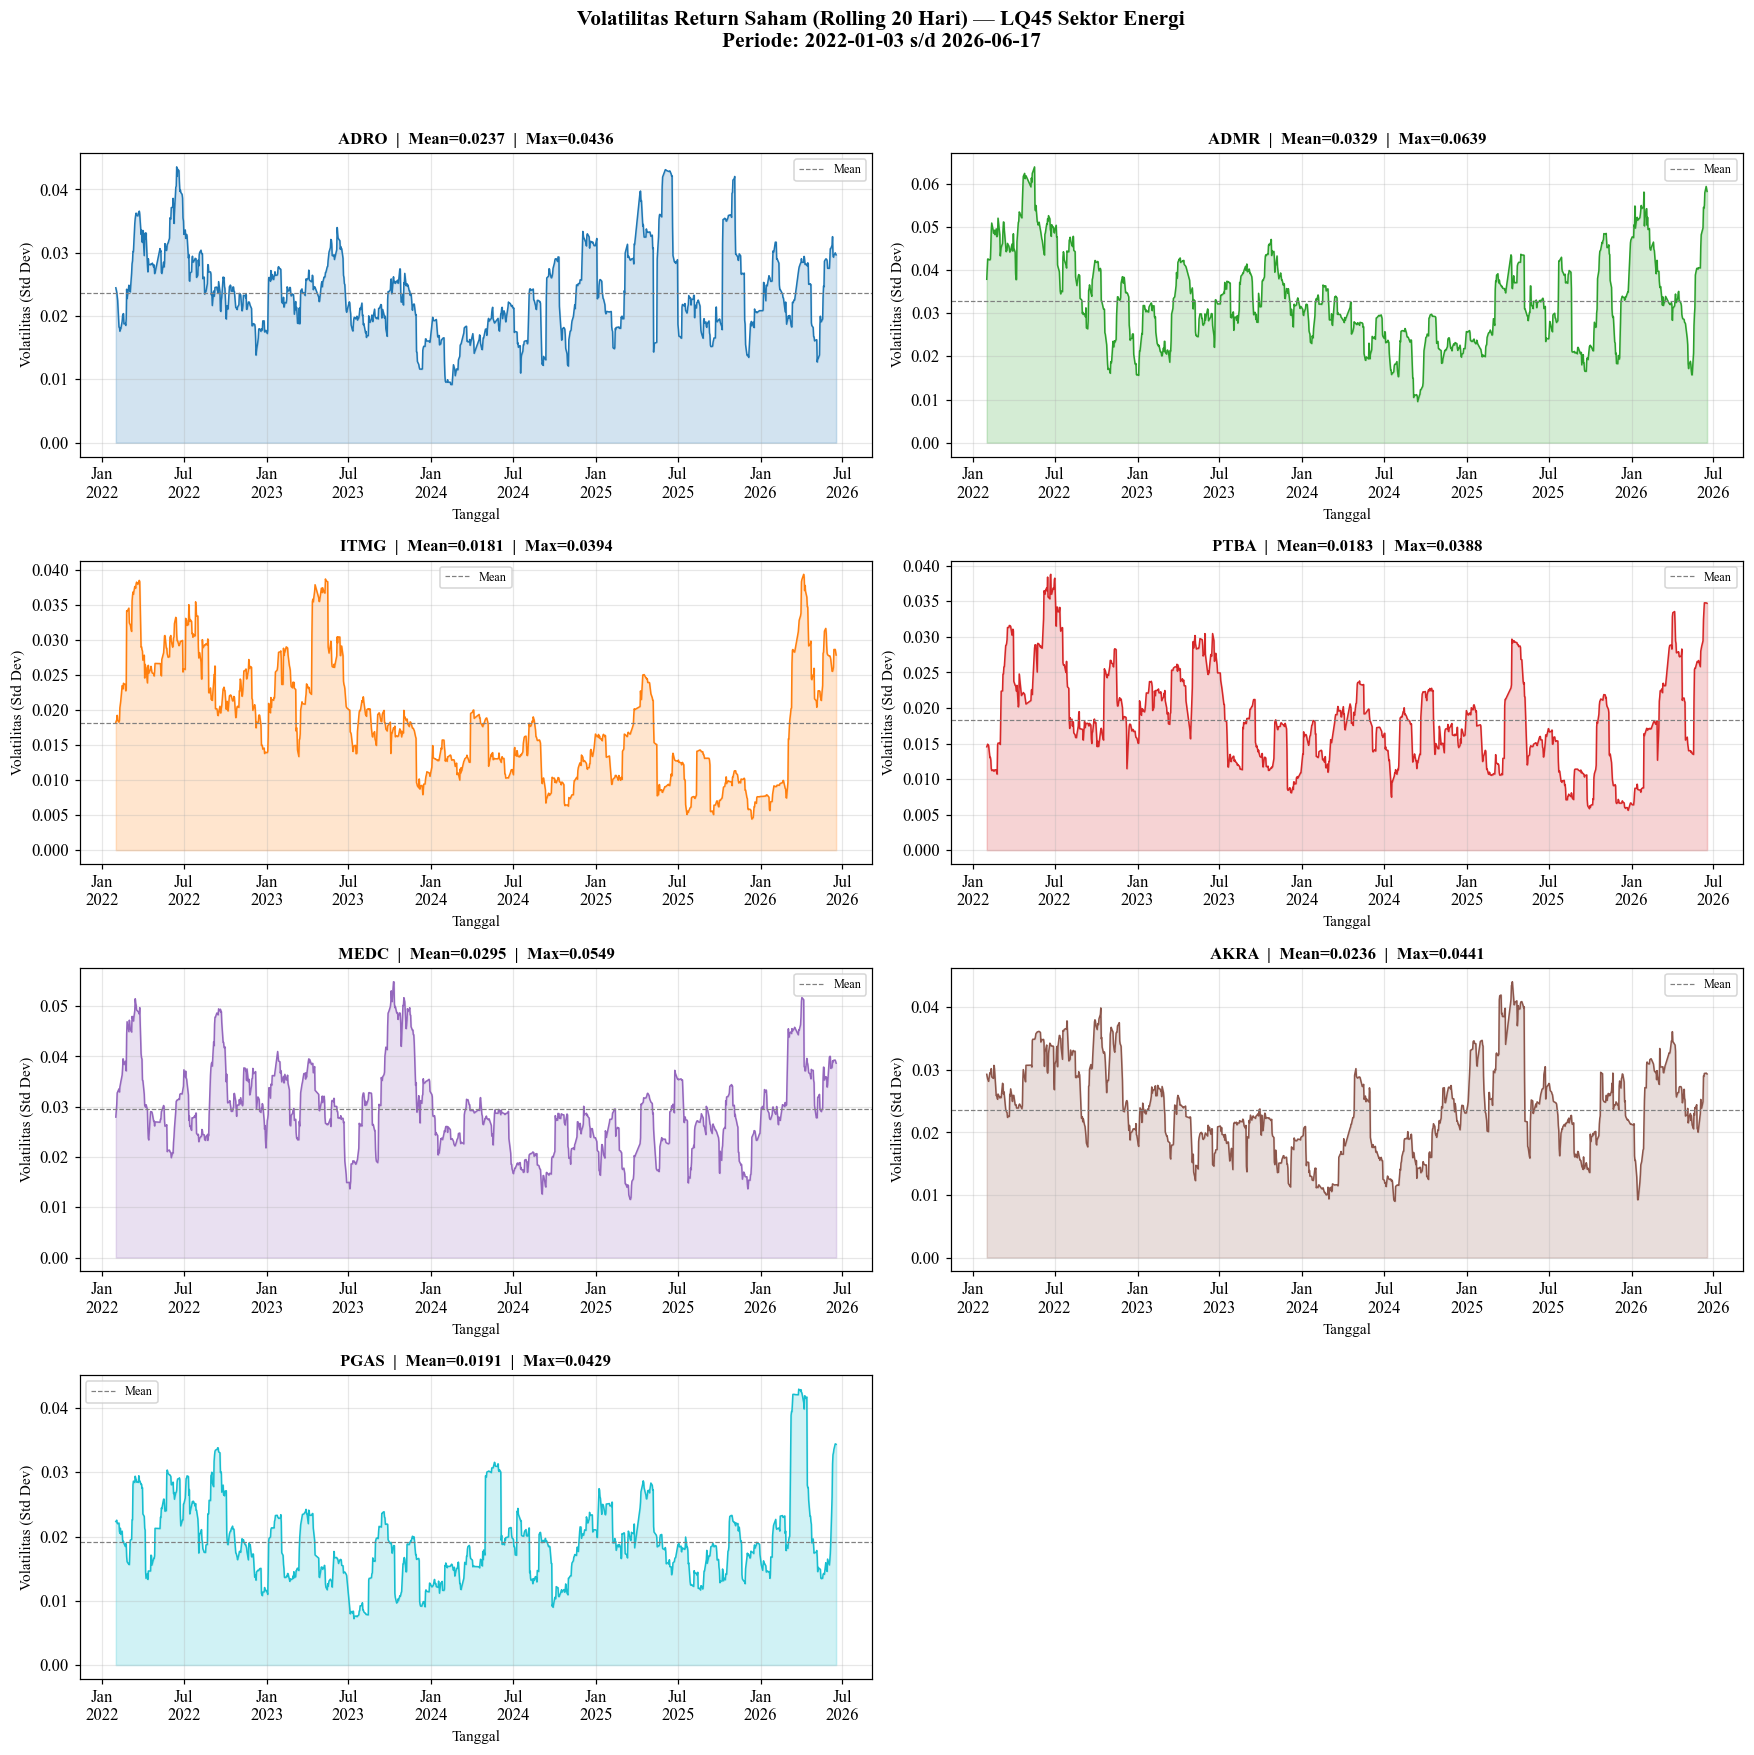

Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_volatilitas_return_per6bulan.png


In [14]:
WARNA = {
    'ADRO': '#1f77b4', 'ADMR': '#2ca02c', 'ITMG': '#ff7f0e',
    'PTBA': '#d62728', 'MEDC': '#9467bd', 'AKRA': '#8c564b', 'PGAS': '#17becf',
}

fig, axes = plt.subplots(4, 2, figsize=(16, 16))
axes = axes.flatten()

fig.suptitle(
    f'Volatilitas Return Saham (Rolling {VOLATILITY_WINDOW} Hari) — LQ45 Sektor Energi\n'
    f'Periode: {START_DATE} s/d {END_DATE}',
    fontsize=14, fontweight='bold', y=0.995
)

for i, kode in enumerate(URUTAN_EMITEN):
    ax = axes[i]
    df_e = df[df['Kode_Emiten'] == kode].dropna(subset=['Volatilitas_Return'])

    ax.plot(
        df_e['Tanggal'], df_e['Volatilitas_Return'],
        color=WARNA[kode], linewidth=1.0
    )
    ax.fill_between(
        df_e['Tanggal'], df_e['Volatilitas_Return'],
        alpha=0.2, color=WARNA[kode]
    )

    vol_mean = df_e['Volatilitas_Return'].mean()
    vol_max  = df_e['Volatilitas_Return'].max()
    ax.axhline(vol_mean, color='gray', linestyle='--', linewidth=0.8, label='Mean')

    ax.set_title(f'{kode}  |  Mean={vol_mean:.4f}  |  Max={vol_max:.4f}',
                  fontsize=11, fontweight='bold')
    ax.set_xlabel('Tanggal')
    ax.set_ylabel('Volatilitas (Std Dev)')

    # Sumbu x per 6 bulan (Jun/Dec)
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))

    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[-1].axis('off')   # panel ke-8 kosong (7 emiten pada grid 4x2)

plt.tight_layout(rect=[0, 0, 1, 0.97])

path_gambar = OUTPUT_DIR_DASHBOARD / 'gambar_volatilitas_return_per6bulan.png'
plt.savefig(path_gambar, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_gambar}")

## 9. Heatmap Korelasi Volatilitas Antar Emiten (Gambar 4.3)

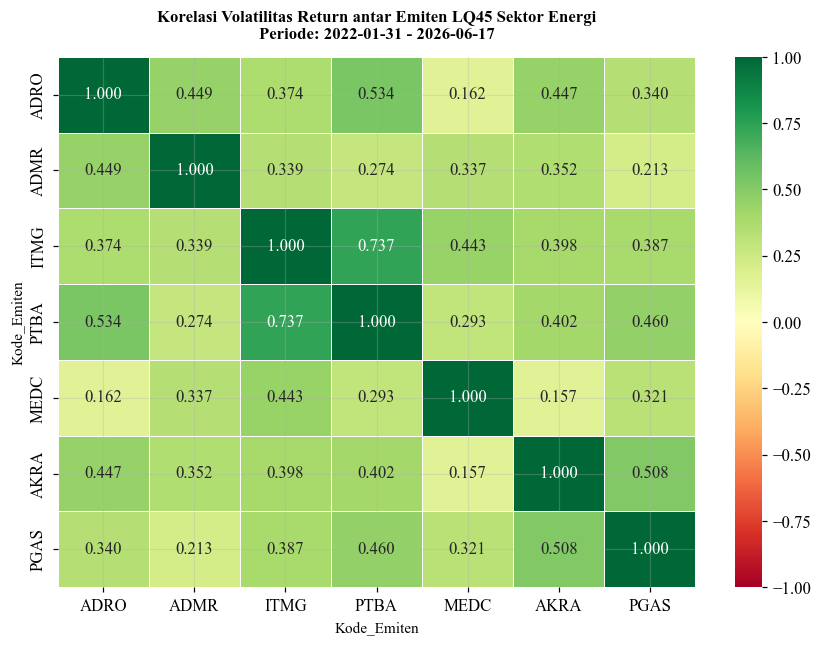

Gambar disimpan: e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\gambar_heatmap_korelasi_volatilitas.png


In [15]:
import seaborn as sns

# Pivot volatilitas return: baris=Tanggal, kolom=7 Emiten
df_pivot_vol = (
    df.pivot_table(index='Tanggal', columns='Kode_Emiten', values='Volatilitas_Return')
      .reindex(columns=URUTAN_EMITEN)
      .dropna()
)

corr_vol = df_pivot_vol.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_vol, annot=True, fmt='.3f', cmap='RdYlGn',
    center=0, linewidths=0.5, vmin=-1, vmax=1, ax=ax
)
ax.set_title(
    f'Korelasi Volatilitas Return antar Emiten LQ45 Sektor Energi\n'
    f'Periode: {df_pivot_vol.index.min().date()} - {df_pivot_vol.index.max().date()}',
    fontweight='bold', pad=12
)
plt.tight_layout()

path_heatmap = OUTPUT_DIR_DASHBOARD / 'gambar_heatmap_korelasi_volatilitas.png'
plt.savefig(path_heatmap, dpi=150, bbox_inches='tight')
plt.show()

print(f"Gambar disimpan: {path_heatmap}")

## 10. Penanganan Baris dengan Nilai NaN

Baris-baris awal pada setiap emiten yang mengandung `NaN` (akibat perhitungan
rolling/lag) **dihapus**, karena belum memiliki nilai fitur teknikal maupun
volatilitas yang valid. Jumlah baris yang hilang per emiten setara dengan
periode rolling terbesar (Stochastic Oscillator, `STOCH_PERIOD` hari).


In [16]:
# ==============================================================================
# CELL — REVISI PEMBERSIHAN BARIS KOSONG (DROPNA MASA WARM-UP)
# ==============================================================================

# 1. Hitung dimensi baris awal sebelum reduksi data panel
jumlah_sebelum = len(df_final)

# 2. Hapus baris yang mengandung NaN (masa warm-up indikator teknikal/lag volatilitas)
df_final_clean = df_final.dropna().reset_index(drop=True)

# 3. Hitung dimensi akhir pasca pembersihan
jumlah_sesudah = len(df_final_clean)
jumlah_dihapus = jumlah_sebelum - jumlah_sesudah
persentase_dihapus = (jumlah_dihapus / jumlah_sebelum * 100) if jumlah_sebelum > 0 else 0

# 4. Format string cetak ke standar pemisah ribuan Indonesia (titik)
str_sebelum = f"{jumlah_sebelum:,}".replace(",", ".")
str_sesudah = f"{jumlah_sesudah:,}".replace(",", ".")
str_dihapus = f"{jumlah_dihapus:,}".replace(",", ".")

print("=" * 70)
print(" ⚙️ LAPORAN REDUKSI OBSERVASI MASA WARM-UP INDIKATOR")
print("=" * 70)
print(f"  Jumlah baris sebelum : {str_sebelum} baris")
print(f"  Jumlah baris sesudah : {str_sesudah} baris (siap untuk modeling)")
print(f"  Jumlah baris dihapus : {str_dihapus} baris ({persentase_dihapus:.2f}%)")
print("-" * 70)

# 5. Tampilkan Distribusi Observasi Valid Tersisa per Emiten Energi
print("  Jumlah observasi siap pakai per emiten:")

# Pastikan daftar urutan emiten ada di locals untuk menghindari NameError
if 'URUTAN_EMITEN' not in locals():
    URUTAN_EMITEN = ['ADRO', 'ADMR', 'ITMG', 'PTBA', 'MEDC', 'AKRA', 'PGAS']

# Menampilkan counts dengan reindex yang aman dari kategori kosong
sebaran_emiten = df_final_clean['Kode_Emiten'].value_counts().reindex(URUTAN_EMITEN).fillna(0).astype(int)

# Tampilkan dalam bentuk series yang rapi di notebook
display(sebaran_emiten)
print("=" * 70)


 ⚙️ LAPORAN REDUKSI OBSERVASI MASA WARM-UP INDIKATOR
  Jumlah baris sebelum : 7.455 baris
  Jumlah baris sesudah : 7.308 baris (siap untuk modeling)
  Jumlah baris dihapus : 147 baris (1.97%)
----------------------------------------------------------------------
  Jumlah observasi siap pakai per emiten:


Kode_Emiten
ADRO    1044
ADMR    1044
ITMG    1044
PTBA    1044
MEDC    1044
AKRA    1044
PGAS    1044
Name: count, dtype: int64

## 11. Simpan Dataset Hasil Preprocessing

Menyimpan dataset final (`technical_features.csv`) yang berisi:
- Fitur teknikal **X1**: OHLCV, RSI, MA(5,10,20), Stochastic %K/%D
- Variabel **Y**: Volatilitas Return

File ini menjadi input pada tahap **Integrasi Dataset** (`05_integrasi_dataset.ipynb`),
digabungkan dengan skor sentimen (**X2**) berdasarkan `Tanggal` dan `Kode_Emiten`.


In [17]:
# ==============================================================================
# CELL FINAL — EKSPOR DATASET PREPROCESSING TEKNIKAL KE LOKASI KANONIK
# ==============================================================================

# 1. Gunakan df_final dari sel sebelumnya (menyesuaikan nama df jika df_final_clean belum terbentuk)
df_final_save = df_final.copy() if 'df_final_clean' not in locals() else df_final_clean.copy()

# 2. Amankan konversi tanggal murni menjadi string ISO murni YYYY-MM-DD
# Ini sangat krusial agar file CSV aman dibuka di Excel tanpa merusak format runtun waktu
df_final_save['Tanggal'] = pd.to_datetime(df_final_save['Tanggal']).dt.strftime('%Y-%m-%d')

# 3. Penyelarasan Jalur Penyimpanan Utama (Kanonik Tesis)
# Memastikan objek file target menggunakan variabel penamaan yang seragam
jalur_ekspor_utama = DIR_PROCESSED / F_TEKNIKAL
simpan_csv(df_final_save, jalur_ekspor_utama)

# 4. Salinan Cadangan untuk Kebutuhan Visualisasi Dashboard (Opsional)
if 'OUTPUT_DIR_DASHBOARD' in locals():
    jalur_ekspor_dashboard = OUTPUT_DIR_DASHBOARD / F_TEKNIKAL
    simpan_csv(df_final_save, jalur_ekspor_dashboard)
    print(f"  💾 Salinan dashboard tersimpan -> {jalur_ekspor_dashboard.name}")

# 5. Cetak Laporan Akhir Monitoring Struktur Data (Format Indonesia Berpemisah Titik)
str_baris = f"{len(df_final_save):,}".replace(",", ".")

print("=" * 80)
print(f"  🎉 SUKSES: Berkas Kanonik Teknikal Berhasil Diekspor!")
print("=" * 80)
print(f"  Lokasi File  : {jalur_ekspor_utama}")
print(f"  Total Baris  : {str_baris} baris (siap masuk tahap gabungan/merge)")
print(f"  Total Kolom  : {len(df_final_save.columns)} variabel")
print(f"  Daftar Kolom : {list(df_final_save.columns)}")
print("=" * 80)


OVERWRITE: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv  (file lama 2026-07-20 02:38 ditimpa)
SAVE  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\03_dataset\processed\technical_features.csv  (7,308 baris)
OVERWRITE: E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\technical_features.csv  (file lama 2026-07-15 17:34 ditimpa)
SAVE  : E:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Penelitian\TESIS_PEMODELAN PREDIKSI VOLATILITAS RETURN SAHAM_2026\dashboard\data\technical_features.csv  (7,308 baris)
  💾 Salinan dashboard tersimpan -> technical_features.csv
  🎉 SUKSES: Berkas Kanonik Teknikal Berhasil Diekspor!
  Lokasi File  : e:\DATA PENTING ILDA NURIDA\DOKUMEN\KULIAH\S2 2025\THESIS\Peneliti

---
## Rekap Output Notebook

| Output | File | Lokasi | Keterangan |
|---|---|---|---|
| Tabel | `tabel_log_return.csv`, `tabel_volatilitas_return.csv` | `03_dataset/raw/` | Pivot lengkap (Tanggal x 7 Emiten) |
| Tabel 4.1 | `tabel_4_1_deskriptif_log_return.csv` | `03_dataset/raw/` | Statistik deskriptif Log Return per emiten |
| Tabel 4.2 | `tabel_4_2_deskriptif_volatilitas.csv` | `03_dataset/raw/` | Statistik deskriptif Volatilitas Return per emiten |
| Gambar 4.1 | `gambar_4_1_log_return.png` | `dashboard/data/` | Time series Log Return 7 emiten |
| Gambar 4.2 | `gambar_volatilitas_return_per6bulan.png` | `dashboard/data/` | Time series Volatilitas Return 7 emiten (per 6 bulan) |
| Gambar 4.3 | `gambar_heatmap_korelasi_volatilitas.png` | `dashboard/data/` | Heatmap korelasi volatilitas antar emiten |
| Dataset fitur teknikal | `technical_features.csv` | `03_dataset/raw/` & `dashboard/data/` | X1 (OHLCV, RSI, MA, Stochastic) + Y (Volatilitas Return), bersih dari NaN |

### Ringkasan Kolom Dataset Output

| Kolom | Kategori | Keterangan |
|---|---|---|
| `Tanggal`, `Kode_Emiten`, `Nama_Perusahaan` | Identitas | Kunci penggabungan dengan data sentimen (X2) |
| `Open, High, Low, Close, Adj Close, Volume` | X1 - OHLCV | Data mentah harga |
| `Log_Return` | Perantara | Basis perhitungan volatilitas |
| `Volatilitas_Return` | **Y (Output)** | Target prediksi - rolling std log return (window 20 hari) |
| `RSI` | X1 - Teknikal | Relative Strength Index (14 hari) |
| `MA_5, MA_10, MA_20` | X1 - Teknikal | Simple Moving Average |
| `Stoch_%K, Stoch_%D` | X1 - Teknikal | Stochastic Oscillator |

### Langkah Selanjutnya

1. **`01_scraping_data/berita_sentimen/`** - Scraping berita Detik/Kontan/Bisnis
   untuk analisis sentimen IndoBERT (**X2**)
2. **`02_preprocessing/sentimen_indobert/`** - Preprocessing teks & scoring
   sentimen menjadi `sentiment_score.csv`
3. **`05_integrasi_dataset.ipynb`** - Merge `technical_features.csv` +
   `sentiment_score.csv` berdasarkan `Tanggal` dan `Kode_Emiten` menjadi
   *Master Dataset* (`dataset_final.csv`)
4. **`04_modeling/`** - Time-Series Split (80:20) -> Modeling XGBoost & LSTM
   (lookback window 10 hari) -> Evaluasi RMSE, MAE, MAPE
